# 12 — Um Gateway por conta, com Identity e Policy locais

**O que vamos demonstrar:** a plataforma orquestra ferramentas de três
contas, mas cada conta decide se aceita a chamada. A pessoa é preservada
por **OBO Entra**, enquanto a audiência e a aplicação chamadora mudam.

**Entregas:** quatro Gateways, quatro providers Identity, quatro engines
Policy em ENFORCE, três Runtimes MCP e um Registry na plataforma.
O agente Strands roda **no kernel deste notebook**, usando Bedrock na
plataforma. As ferramentas são executadas nos Runtimes AWS.

Comece pelo [runbook](../docs/federation/README.md).
Kernel: `.venv/bin/python`, após `uv sync --frozen --extra banking`.
Reserve 60–90 minutos após preparar identidades, contas e Knowledge Base.

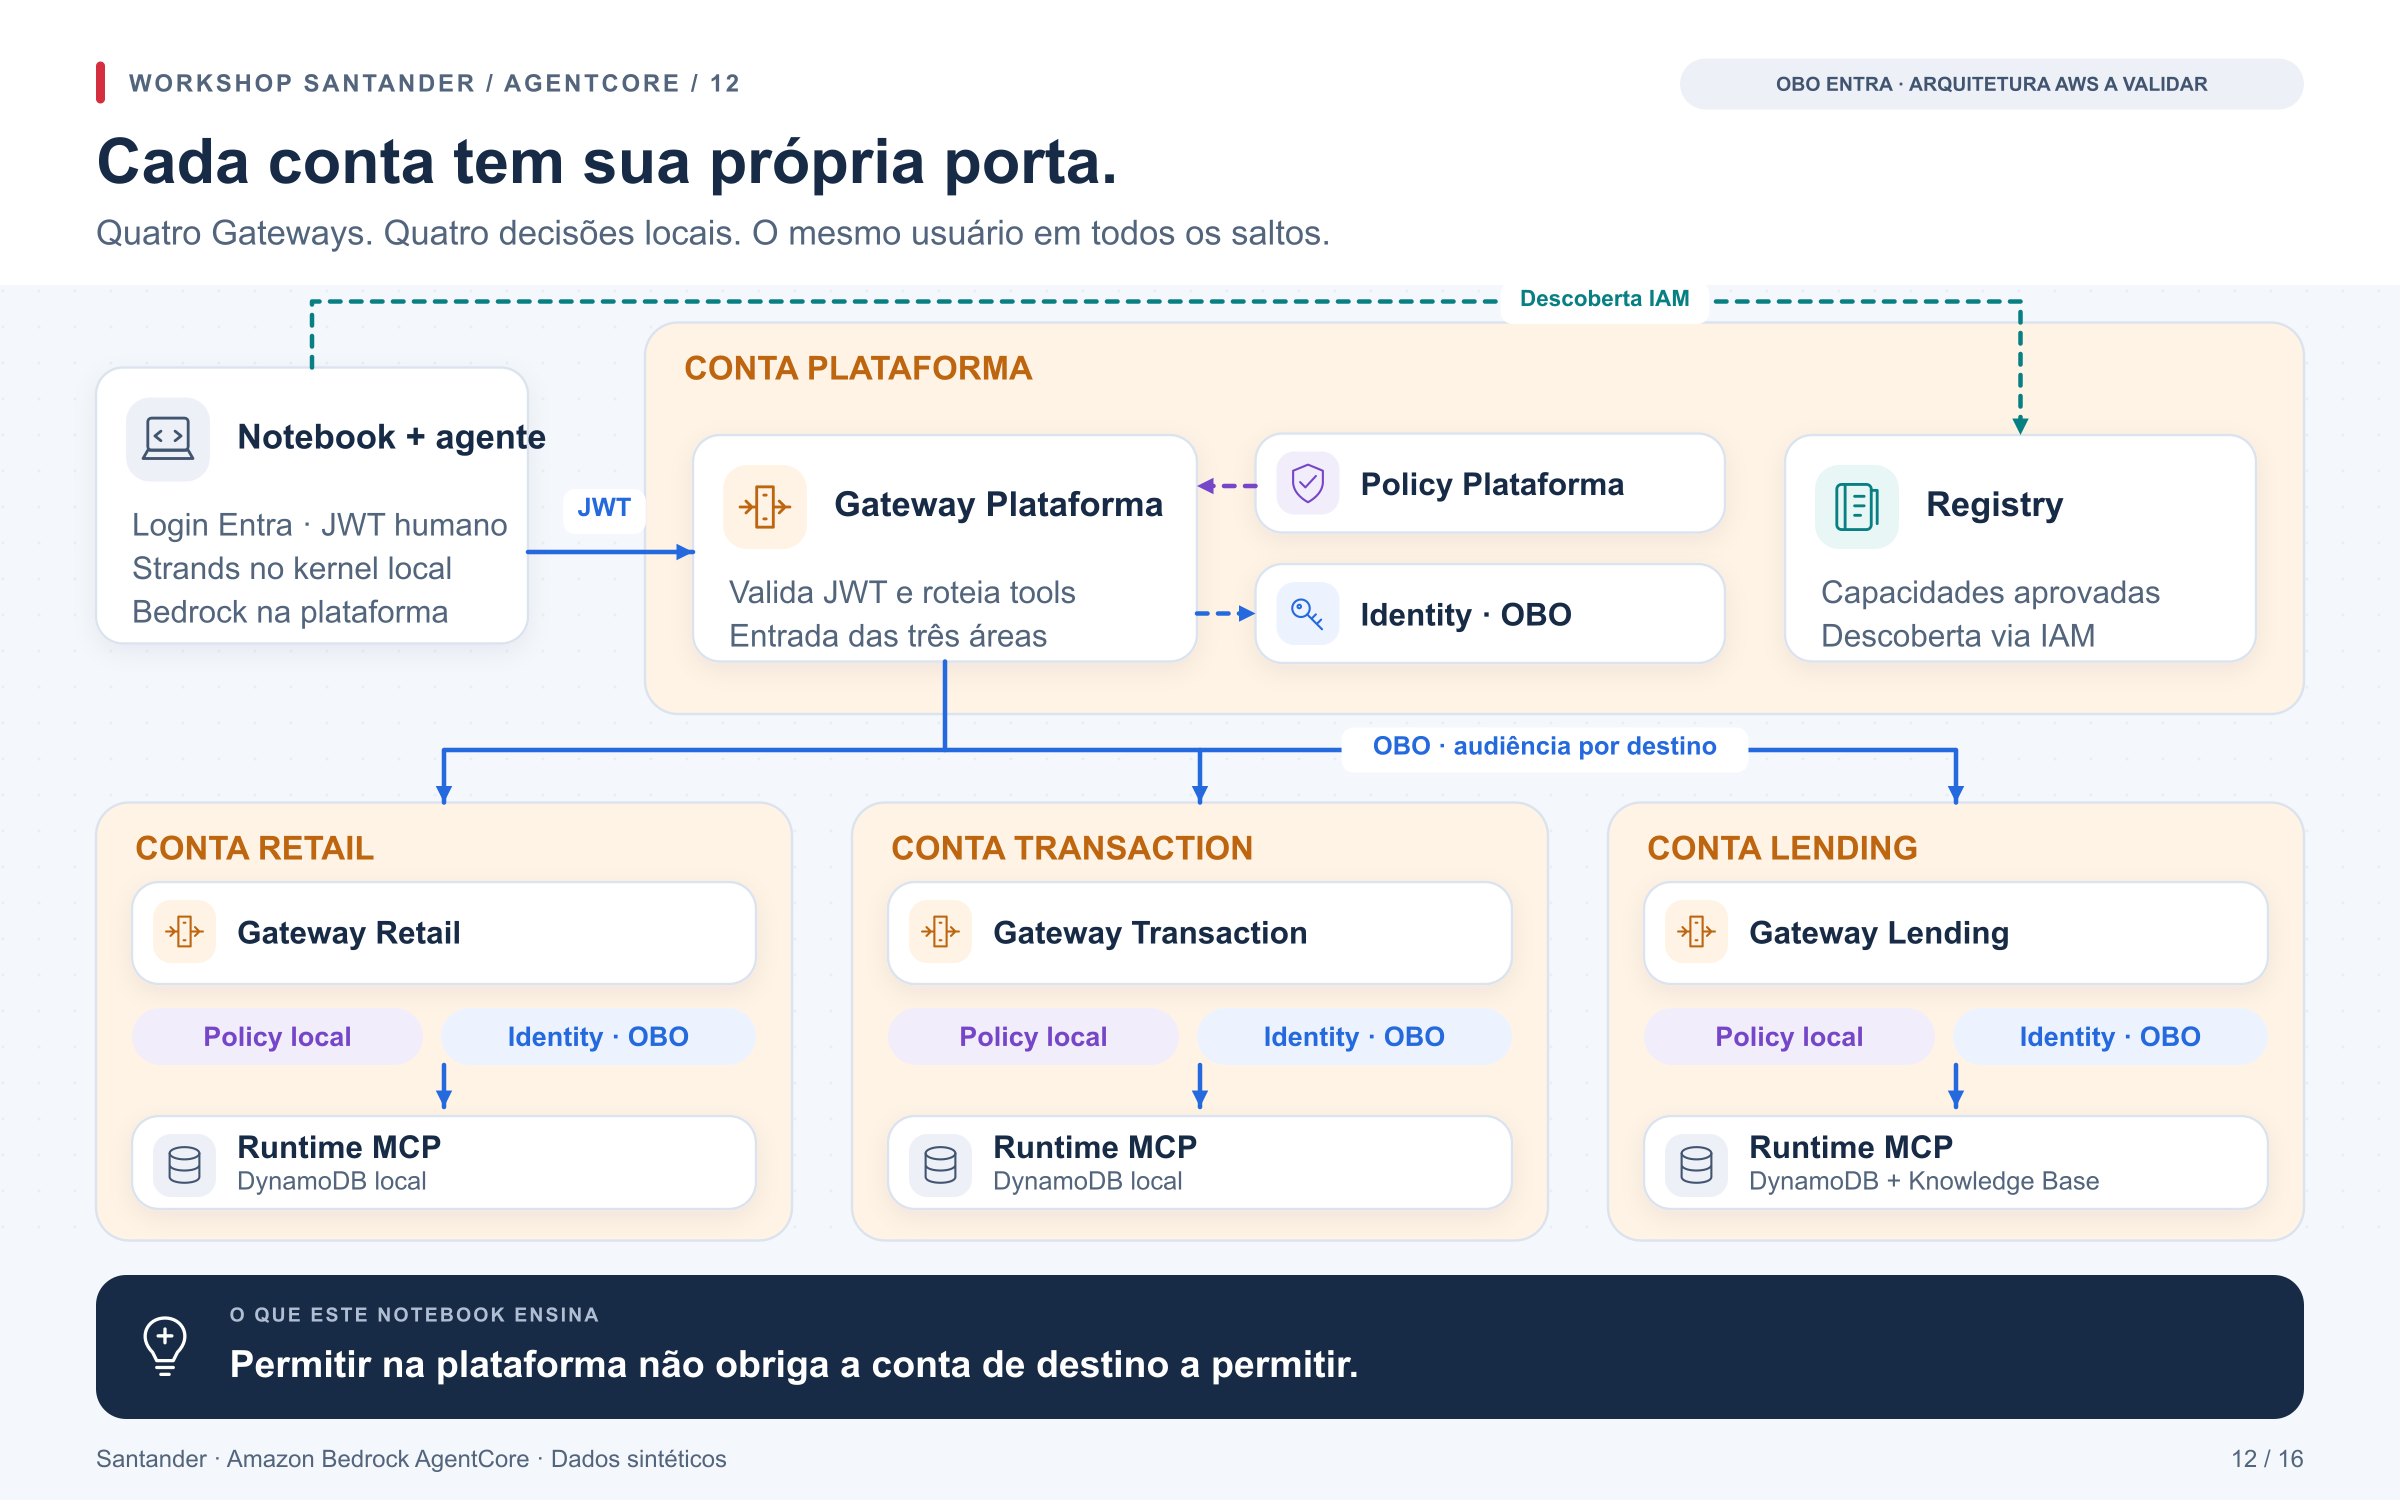

[Ampliar PNG](../docs/federation/arquitetura.png) · [SVG](../docs/federation/arquitetura.svg)

**Etapa 13 de 17 na jornada.** [Jornada completa](../docs/jornada.md) · [Anterior: Agente central e três áreas](11_blog_multi_account_gateway_mcp.ipynb) · [Próximo: Identidade na fonte](13_databricks_e_evidencias.ipynb)

## Conceitos para acompanhar este laboratório

**Federação de Gateways** preserva decisões independentes: permitir na
plataforma não obriga a área de negócio a permitir. O nome
`retail___backend___get_profile` reflete os dois targets atravessados.

Em cada troca **OBO**, o destinatário (`aud`) e a aplicação (`azp`) podem
mudar. A pessoa continua identificada por `tid` + `oid`; `sub` pode variar
entre aplicações. **Whoami** é uma ferramenta diagnóstica que verifica
o JWT recebido e relata uma prova reduzida da identidade.

Veja `verify_chain()` em
[federation/client.py](../src/santander_demo/federation/client.py)
e a verificação no destino em
[runtime_identity.py](../src/santander_demo/federation/runtime_identity.py).
A delegação termina nos MCPs; DynamoDB e KB continuam usando roles IAM
das LOBs. Isso não comprova grants individuais nessas duas fontes.

**Documentação oficial para aprofundar:**

* [Entra: fluxo OBO](https://learn.microsoft.com/pt-br/entra/identity-platform/v2-oauth2-on-behalf-of-flow)
* [AgentCore Identity: troca OBO](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/on-behalf-of-token-exchange.html)
* [Entrada JWT no AgentCore](https://docs.aws.amazon.com/bedrock-agentcore/latest/devguide/inbound-jwt-authorizer.html)

As explicações estão em português; nomes de APIs, claims e campos permanecem como aparecem no código. As páginas oficiais podem estar em inglês.

## 1. Entenda os três controles em cada passagem

| Controle | Pergunta respondida |
|---|---|
| Authorizer do Gateway | O JWT é válido, destinado a esta API e emitido para a aplicação esperada? |
| Policy local | Este usuário e aplicação podem chamar esta tool com estes parâmetros? |
| Identity local | O IdP permite obter um token delegado para a próxima API? |

A plataforma usa seu Identity para chamar o **Gateway da LOB**. A LOB usa
seu próprio Identity para chamar **seu Runtime MCP**. O Runtime exige o
workload do Gateway local. Cada Policy consulta `tid`, `oid`, `azp` e `scp`.

**Diferença para o notebook 11:** no artigo, um Gateway central chama
diretamente os MCPs com M2M. Aqui os Gateways são encadeados e a delegação
humana continua até os destinos. Os resultados retornam à plataforma.

**Na próxima célula**, vamos importar os helpers, localizar o projeto e
definir os controles do laboratório. `RUN_AWS=False` mantém a preparação
offline; `DEPLOY_PHASE` escolhe uma fase de implantação. `LIVE` só fica
ativo com AWS habilitada e nenhuma fase selecionada.
`RUN_PIPELINE` e `APPLY_CHANGESET` controlarão o wrapper de IaC, enquanto
`RUN_AGENT` habilitará a etapa opcional com Bedrock. A saída mostrará o
modo escolhido; reexecute esta célula sempre que alterar os controles.

In [ ]:
import json
import subprocess
import sys
from pathlib import Path
from IPython.display import Markdown, display
from santander_demo.federation.spec import ACCOUNTS, central_name, local_matrix, tools_by_lob
from santander_demo.federation.client import (
    load_config, aws_sessions, prepare_phase, preflight, login, verify_token,
    verify_chain, probe_policy, probe_wrong_audience,
)
from santander_demo.banking.client import call_tool
from santander_demo.banking.spec import LOBS

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "infra/federation").is_dir()

RUN_AWS = False
DEPLOY_PHASE = None  # bootstrap / gateways / backends / domain-bindings / platform-bindings / registry
RUN_PIPELINE = False
APPLY_CHANGESET = False
RUN_AGENT = False  # opcional: inferência Bedrock; primeiro prove os caminhos MCP
CONFIG_PATH = ROOT / "config/local.federation.json"
LIVE = RUN_AWS and DEPLOY_PHASE is None
print("AWS REAL" if RUN_AWS else "PREPARAÇÃO LOCAL — AWS e OAuth: NOT_RUN")

## 2. Veja uma autorização terminar no segundo Gateway

Esta célula avalia o **Cedar real localmente**, usando a mesma fonte dos
templates. Não emite tokens nem simula respostas de backend.

| Consulta didática | Plataforma | Retail | Resultado |
|---|---|---|---|
| get_profile(C003) | Permite | Permite | Caminho autorizado |
| get_profile(C007) | Nega | Nem precisa ser chamada | Para na plataforma |
| get_profile(C008) | Permite | Nega | Para na conta Retail |

O resultado `retail_policy_isolated` mostra o que a Policy Retail decidiria
isoladamente. Se a plataforma nega, essa etapa não é executada no fluxo.
As negativas C007/C008 pertencem apenas à tool `get_profile`.

Vamos executar `local_matrix()` e exibir suas decisões para comparar
os três clientes da tabela. As asserções comparam as decisões com a
tabela escrita, além de confirmar `oauth_and_aws: NOT_RUN`.
O resultado desta célula verifica as regras
Cedar locais, enquanto os testes de identidade e dos Gateways AWS virão depois.

In [ ]:
matrix = local_matrix()
display(matrix)
assert [
    (r["customer"], r["platform_policy"], r["retail_policy_isolated"], r["end_to_end_contract"])
    for r in matrix["cases"]
] == [
    ("C003", "ALLOW", "ALLOW", "ALLOW"),
    ("C007", "DENY", "ALLOW", "DENY"),
    ("C008", "ALLOW", "DENY", "DENY"),
], "As decisões divergem da matriz descrita"
assert matrix["oauth_and_aws"] == "NOT_RUN"

## 3. Prepare o ambiente por IaC

As identidades Entra são pré-requisitos: login público, quatro aplicações
de Gateway e três APIs de Runtime; grants OBO e quatro segredos nas contas
locais. O [runbook](../docs/federation/README.md) detalha todas as relações.
O módulo Entra da trilha original não configura esta variante.

No terminal:

```bash
uv run --extra banking python scripts/build_artifacts.py --banking
cp config/federation.example.json config/local.federation.json
```

Preencha perfis, contas, tenant, aplicações, ARNs de segredo, usuário e KB.
Nenhum valor de segredo ou token deve ser salvo no JSON ou notebook.
A célula abaixo gera **somente arquivos locais**.

Vamos executar `infra/federation/generate.py` com o Python deste kernel
e listar os JSONs gerados para confirmar a existência de treze templates,
usados nos dezesseis stacks previstos. A saída também mostrará o comando
de lint; esse comando será apenas exibido, não executado por esta célula.

In [ ]:
subprocess.run([sys.executable, str(ROOT / "infra/federation/generate.py")], cwd=ROOT, check=True)
templates = sorted((ROOT / "infra/federation/templates").glob("*.json"))
assert len(templates) == 13
print("13 templates locais / 16 stacks previstos / nenhum recurso criado.")
print("Lint: uv run --extra banking cfn-lint infra/federation/templates/*.json")

## 4. Implante por fases

| Fase | Onde / o que |
|---|---|
| bootstrap | Quatro buckets de artefatos |
| gateways | Gateway + Identity + Policy engine + logs em cada conta |
| backends | Runtime MCP + DynamoDB nas três LOBs |
| domain-bindings | Gateway local → seu Runtime e Policies locais |
| platform-bindings | Gateway Plataforma → três Gateways e Policy central |
| registry | Metadados aprovados para descoberta |

Use `RUN_AWS=True` e uma fase por vez. Com `RUN_PIPELINE=False`, apenas
os parâmetros e comandos são preparados. Com `RUN_PIPELINE=True`, o
wrapper prepara change sets (inclui upload do artefato); depois da revisão,
`APPLY_CHANGESET=True` aplica pelo CloudFormation.

Na fase inicial os engines ainda não têm permits: chamadas ficam negadas.
Se algo falhar, corrija IaC/parâmetros e repita a fase. Não há criação ou
correção de recursos por SDK no notebook.

Vamos carregar a configuração e validar os perfis via STS quando
`RUN_AWS` estiver ativo. Com uma fase selecionada, a célula exibirá os
planos por conta e, se `RUN_PIPELINE=True`, executará o wrapper do projeto.
`APPLY_CHANGESET=True` acrescentará `--execute`. No padrão offline,
a saída será `NOT_RUN` para STS, change sets e implantação.

In [ ]:
config = sessions = None
if RUN_AWS:
    config = load_config(CONFIG_PATH)
    sessions = aws_sessions(config)
    if DEPLOY_PHASE is not None:
        plans = prepare_phase(ROOT, config, sessions, DEPLOY_PHASE)
        for plan in plans:
            print(plan["account"], plan["command"], sep="\n")
        if RUN_PIPELINE:
            for plan in plans:
                subprocess.run(
                    plan["args"] + (["--execute"] if APPLY_CHANGESET else []),
                    cwd=ROOT, check=True,
                )
else:
    print("NOT_RUN: STS, change sets e implantação.")

## 5. Confira quatro fronteiras independentes

Depois da implantação, volte a `DEPLOY_PHASE=None` e reexecute a célula
de configuração. O preflight lê os quatro Gateways, verifica Cedar
implantado, OBO local, audiências, callers, targets e restrição de workload
dos Runtimes. Configuração pronta ainda não prova chamadas bem-sucedidas.

Vamos armazenar os identificadores validados em `environment` e exibir
o número de Gateways, o modo das Policies e os log groups de cada conta.
Esperamos quatro Gateways e `invocation_verified: False`, pois as
chamadas ainda não ocorreram. Com `LIVE=False`, o preflight será ignorado.

In [ ]:
environment = None
if LIVE:
    environment = preflight(config, sessions)
    print({"mode": environment["mode"], "gateways": len(environment["gateways"]),
           "policy": "ENFORCE em quatro contas", "invocation_verified": False})
    display({account: values["GatewayLogGroup"] for account, values in environment["gateways"].items()})
else:
    print("NOT_RUN: preflight AWS.")

## 6. Autentique uma pessoa, não uma credencial M2M

O login solicita `api://<gateway-plataforma>/access_as_user`. A audiência
do token v2 é o App ID da plataforma; `azp` é o App ID do login público.
O token fica só na memória. Use o usuário esperado nas quatro allowlists.

Se Device Code não for permitido, substitua somente a linha `login(config)`
por `getpass.getpass(...)` para um access token obtido pelo fluxo interativo
aprovado dessa aplicação. `verify_token` continua obrigatório.

Vamos obter o token em `user_token` e executar `verify_token` antes
de chamar as ferramentas. A saída será o resumo da verificação; uma
falha de validação interromperá esta etapa. Com `LIVE=False`, o login
não será iniciado e a saída indicará `NOT_RUN`.

In [ ]:
user_token = None
if LIVE:
    user_token = login(config)
    display(verify_token(user_token, config))
else:
    print("NOT_RUN: login e verificação Entra.")

## 7. Descubra ferramentas sem pular os Gateways

O Registry publica o endpoint da **plataforma**, com nomes que carregam
as duas camadas: `retail___backend___get_profile`.
O cliente não usa o Registry para pegar um endpoint de backend e contornar
a Policy. Schemas estáticos evitam sincronização que dependeria de usuário.

Vamos primeiro exibir os contratos locais agrupados por LOB, disponíveis
mesmo offline. Em modo live, consultaremos também o Registry pela sessão
da plataforma e exibiremos as capacidades aprovadas. Esta célula realiza
descoberta de metadados; as chamadas MCP serão feitas nas próximas etapas.

In [ ]:
display(tools_by_lob())
if LIVE:
    from santander_demo.federation.agent import discover
    display(discover(sessions["platform"], environment))
else:
    print("Contratos locais exibidos; busca no Registry: NOT_RUN.")

## 8. Prove a identidade que chegou aos três MCPs

Cada `whoami` verifica o JWT recebido no Runtime usando JWKS do tenant.
Esperamos a mesma pessoa (`hash(tid:oid)`), `azp` do Gateway local e `aud`
do Runtime local. Não compare `sub` entre aplicações.
Nenhuma claim é aceita a partir de argumentos de tool.

Vamos usar `verify_chain` para chamar as ferramentas de identidade pelos
caminhos federados e comparar as provas dos três destinos com a
configuração esperada. O resultado ficará em `identity_evidence` para
a exportação final. Com `LIVE=False`, as trocas OBO e a verificação
nos Runtimes permanecerão como `NOT_RUN`.

In [ ]:
identity_evidence = {"mode": "NOT_RUN"}
if LIVE:
    identity_evidence = await verify_chain(environment, user_token, config)
    display(identity_evidence)
else:
    print("NOT_RUN: duas trocas OBO por caminho e verificação nos Runtimes.")

## 9. Consulte as três contas pelo Gateway da plataforma

São chamadas MCP determinísticas, antes de introduzir decisões do LLM.
Cada resultado atravessa **duas Policies** e **duas trocas OBO**.

Vamos consultar perfil em Retail, pagamentos em Transaction e score
em Lending para o cliente sintético `C003`. `central_name` montará os
nomes qualificados anunciados pela plataforma, e as respostas serão
armazenadas em `observations`. Esperamos uma entrada para cada LOB;
com `LIVE=False`, nenhuma consulta será realizada.

In [ ]:
observations = {}
if LIVE:
    for lob, tool in [
        ("retail-banking", "get_profile"),
        ("transaction-banking", "get_payments"),
        ("lending-wealth", "get_credit_score"),
    ]:
        observations[lob] = await call_tool(
            environment, user_token, central_name(lob, tool), {"customer_id": "C003"}
        )
    display(observations)
    assert set(observations) == set(LOBS)
else:
    print("NOT_RUN: consultas em quatro contas.")

## 10. Compare uma negativa central e uma negativa local

C007 deve parar na plataforma. C008 deve passar pela plataforma e parar
na Policy Retail. O código não altera permissões durante a demonstração.
São tentativas de leitura; nenhum dado será escrito.

Uma resposta de Policy comprova que houve negação. Para atribuir o salto
e comprovar ausência de execução no backend, confira os log groups das
contas na janela da chamada. Erro OAuth/rede não conta como negação Cedar.

Vamos executar `probe_policy` para cada cliente e guardar os resultados
em `denials`. Cada tentativa deverá retornar `POLICY_DENIAL_REPORTED`;
qualquer outro resultado fará a asserção falhar. Offline, a célula
lembrará que somente a matriz Cedar da seção 2 foi executada.

In [ ]:
denials = []
if LIVE:
    for customer in ["C007", "C008"]:
        denial = await probe_policy(environment, user_token, customer)
        display(denial)
        denials.append(denial)
        assert denial["outcome"] == "POLICY_DENIAL_REPORTED", (
            "Negativa de Policy não comprovada; revise logs e integração."
        )
else:
    print("NOT_RUN: negativas nos Gateways AWS. Cedar local foi testado na seção 2.")

## 11. Tente reutilizar um token na conta errada

O JWT da plataforma é enviado ao Gateway Retail somente como teste negativo.
Ele tem audiência e aplicação incompatíveis com essa entrada. Esperamos
HTTP 401/403. Esse teste não substitui o ensaio da restrição de workload
do Runtime com um token que já tenha audiência válida.

Vamos chamar `probe_wrong_audience` e salvar a evidência em
`auth_evidence`. O helper verificará a recusa de autenticação antes de
devolver o resultado, separando esse caso das negativas de Policy da
seção anterior. Com `LIVE=False`, a tentativa não será enviada.

In [ ]:
auth_evidence = {"mode": "NOT_RUN"}
if LIVE:
    auth_evidence = await probe_wrong_audience(environment, user_token)
    display(auth_evidence)
else:
    print("NOT_RUN: rejeição de audiência/aplicação incorretas.")

## 12. Opcional: faça a pergunta ao agente Strands

Ative `RUN_AGENT=True` e reexecute a configuração. O agente roda neste
notebook; Bedrock usa o perfil da plataforma. A seleção de tools não
substitui nenhuma das quatro Policies. Registry e Guardrail também são
chamados na AWS. As respostas são somente para a demo com fixtures.

Com `LIVE` e `RUN_AGENT` ativos, vamos pedir ao agente consultas sobre
`C003` nas três áreas. A célula exibirá a resposta em português e o
histórico de ferramentas, exigindo ao menos uma chamada bem-sucedida
por LOB. Se algum dos controles estiver desativado, `agent_result`
permanecerá vazio e a inferência será marcada como `NOT_RUN`.

In [ ]:
agent_result = None
if LIVE and RUN_AGENT:
    from santander_demo.federation.agent import run_agent
    agent_result = run_agent(
        "Consulte perfil e contas, pagamentos, score e empréstimos de C003 nas "
        "três áreas. Responda em português, cite as ferramentas e não faça alterações "
        "nem trate os dados sintéticos como uma decisão real de crédito.",
        user_token, environment, sessions["platform"],
    )
    display(Markdown(agent_result["response"]))
    display(agent_result["tool_calls"])
    observed = {c["lob"] for c in agent_result["tool_calls"] if c["status"] == "success"}
    assert set(LOBS) <= observed, "O agente não consultou as três áreas."
else:
    print("NOT_RUN: inferência Strands/Bedrock opcional.")

## 13. Registre somente o que foi observado

A evidência não contém JWT, claims brutas, resposta bancária ou documentos.
A atribuição da negativa ao Gateway correto e a ausência de chamada ao
backend continuam pendentes até a revisão dos logs. Os recursos não são
removidos automaticamente; use CloudFormation na ordem inversa do runbook.

No modo live, vamos reunir horário, contagem de Gateways, provas de
identidade, consultas observadas e resultados negativos em
`evidence/federation.json`, substituindo o arquivo anterior se existir.
Os campos pendentes permanecerão explícitos, incluindo a revisão dos
logs e o teste de acesso direto ao Runtime com audiência válida.
Offline, exibiremos os status de preparação sem salvar evidência AWS.
Ao final, `user_token` será definido como `None`.

In [ ]:
if LIVE:
    from datetime import datetime, timezone
    evidence = {
        "mode": "AWS_LIVE", "observed_at": datetime.now(timezone.utc).isoformat(),
        "gateway_count": len(environment["gateways"]),
        "obo": identity_evidence,
        "lob_calls_observed": sorted(observations),
        "policy_denials": denials,
        "wrong_audience": auth_evidence,
        "strands_bedrock": "OBSERVED" if agent_result else "NOT_RUN",
        "negative_boundary_and_no_backend_execution": "LOG_REVIEW_PENDING",
        "valid_audience_runtime_workload_bypass_test": "NOT_RUN",
    }
    target = ROOT / "evidence/federation.json"
    target.parent.mkdir(exist_ok=True)
    target.write_text(json.dumps(evidence, indent=2) + "\n")
    display(evidence)
else:
    display({
        "mode": "OFFLINE_PREPARATION",
        "local_cedar": "PASS",
        "aws_gateways": "NOT_RUN", "identity_obo": "NOT_RUN",
        "policy_service": "NOT_RUN", "registry": "NOT_RUN",
    })
user_token = None

## Limpeza — recursos do laboratório

Ao encerrar o notebook 12, siga a ordem inversa das dependências:

| Ordem | Templates dos stacks | Contas |
|---|---|---|
| 1 | `registry` | Plataforma |
| 2 | `platform-bindings` | Plataforma |
| 3 | `retail-banking-bindings`, `transaction-banking-bindings`, `lending-wealth-bindings` | LOBs |
| 4 | `retail-banking-backend`, `transaction-banking-backend`, `lending-wealth-backend` | LOBs |
| 5 | `platform-gateway` e os três templates `*-gateway` das LOBs | Quatro contas |
| 6 | `bootstrap` | Cada uma das quatro contas |

Execute uma remoção por vez e aguarde sua conclusão. Tabelas, fixtures e
buckets têm `Retain`; identidades Entra, grants, segredos e KB são geridos
pelos stacks de seus proprietários. Remover esta trilha não remove o
ambiente do notebook 11. Consulte o
[runbook da federação](../docs/federation/README.md) e o
[procedimento de cleanup](../docs/cleanup.md).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "federation",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Limpeza — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['APPLY_CHANGESET', 'CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET',
 'CONFIG_PATH', 'DEPLOY_PHASE', 'LIVE', 'MODE', 'RUN_AGENT', 'RUN_AWS', 'RUN_PIPELINE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'agent_result', 'auth_evidence', 'cloud', 'config', 'customer',
 'denial', 'denials', 'environment', 'evidence', 'identity', 'identity_evidence', 'lab',
 'lob', 'matrix', 'observations', 'observed', 'plan', 'plans', 'sessions', 'target',
 'templates', 'token', 'tool', 'user_token']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json